# UTH Computer Vision Coursework — Topic 11: Facial Occlusion & Artifact Detection
## 🔬 Notebook 07: Khám Phá & Kiểm Toán Toàn Diện Bộ Benchmark 50k (Universal Multi-Method Suite)

> **Bối cảnh nghiên cứu & vai trò bộ dữ liệu**:
> - **Tên bộ kiểm định**: Universal Multi-Method Deepfake Benchmark Suite (`deepfake_test_suite_50k`)
> - **Tổng quy mô**: **50.084 ảnh** (3.9 GB) trên **39 phương pháp** (1 nhóm ảnh thật + 38 phương pháp sinh ảnh giả SOTA).
> - **Mục tiêu cốt lõi**: Khám phá cấu trúc, độ phân giải, họ công nghệ và đo lường quang học; đồng thời cung cấp **phân tích khoa học về việc chọn lọc / loại trừ dữ liệu dị thường** khi thiết lập benchmark kiểm định mô hình detector.

| Chỉ Số Kiểm Định | Giá Trị Thực Tế |
| :--- | :--- |
| **Tổng số lượng ảnh (Full Split)** | 50.084 ảnh (25.042 Thật vs 25.042 Giả — Tỷ lệ $1:1$ cân bằng tuyệt đối) |
| **Tập chuẩn hóa (Balanced Split)** | 21.446 ảnh (Chuẩn 300 ảnh/phương pháp) |
| **Họ công nghệ sinh ảnh giả** | 6 họ chính (Diffusion Transformers, GANs, Face Swapping, Reenactment, Latent Diffusion, Editing) |
| **Cam kết rò rỉ danh tính** | **Zero Identity Leakage** (Độc lập 100% với CelebA-HQ và tập huấn luyện) |


In [1]:
# --- [1. CẤU HÌNH MÔI TRƯỜNG & NẠP CÁC MODULE CHUYÊN DỤNG] ---
import os
from pathlib import Path
import sys

# Thiết lập đường dẫn gốc workspace
project_root = Path.cwd().resolve()
while project_root.name != "uth-cv-coursework" and project_root.parent != project_root:
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
os.chdir(project_root)

import csv
import json
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import cv2

print(f"[✓] Workspace Root: {project_root}")
print("[✓] Đã sẵn sàng các thư viện xử lý ảnh và thị giác máy tính.")


[✓] Workspace Root: /home/bush/Projects/uth-cv-coursework
[✓] Đã sẵn sàng các thư viện xử lý ảnh và thị giác máy tính.


### 2. Nạp Dữ Liệu Metadata & Xác Thực Tính Cân Bằng Lớp (Class Balance)

Bộ dữ liệu cung cấp 2 phân tách kiểm định độc lập:
1. `test_coursework_44methods_full_zero_leakage.csv`: Tập toàn diện 50.084 ảnh.
2. `test_coursework_44methods_balanced_zero_leakage.csv`: Tập cân bằng 21.446 ảnh.


In [2]:
# --- [2. NẠP VÀ KIỂM TRA TẬP DỮ LIỆU SPLITS] ---
full_csv = Path("data/benchmarks/deepfake_test_suite_50k/splits/test_coursework_44methods_full_zero_leakage.csv")
bal_csv = Path("data/benchmarks/deepfake_test_suite_50k/splits/test_coursework_44methods_balanced_zero_leakage.csv")

with open(full_csv, "r", encoding="utf-8") as f:
    full_rows = list(csv.DictReader(f))

with open(bal_csv, "r", encoding="utf-8") as f:
    bal_rows = list(csv.DictReader(f))

print(f"[✓] Full Split: {len(full_rows):,} samples")
full_lbl = Counter(r['label'] for r in full_rows)
print(f"    - Real (0): {full_lbl['0']:,} ({full_lbl['0']/len(full_rows)*100:.2f}%)")
print(f"    - Fake (1): {full_lbl['1']:,} ({full_lbl['1']/len(full_rows)*100:.2f}%)")

print(f"\n[✓] Balanced Split: {len(bal_rows):,} samples")
bal_lbl = Counter(r['label'] for r in bal_rows)
print(f"    - Real (0): {bal_lbl['0']:,} ({bal_lbl['0']/len(bal_rows)*100:.2f}%)")
print(f"    - Fake (1): {bal_lbl['1']:,} ({bal_lbl['1']/len(bal_rows)*100:.2f}%)")


[✓] Full Split: 50,084 samples
    - Real (0): 25,042 (50.00%)
    - Fake (1): 25,042 (50.00%)

[✓] Balanced Split: 21,446 samples
    - Real (0): 10,723 (50.00%)
    - Fake (1): 10,723 (50.00%)


### 3. Phân Bố Theo 6 Họ Công Nghệ Sinh Ảnh Giả (Taxonomy Breakdown)

Bộ dữ liệu phân bổ toàn diện qua 6 nhóm công nghệ thị giác máy tính:
- **Real Faces**: Ảnh thật chất lượng cao từ FFHQ, FF++ C23 và CelebA-real.
- **Face Swapping**: Hoán đổi khuôn mặt (8 phương pháp).
- **Reenactment / Talking Head**: Tái tạo khẩu hình và chuyển động (10 phương pháp).
- **GAN Architectures**: Các mô hình đối nghịch StyleGAN2/3/XL, StarGAN.
- **Diffusion Transformers (DiT)**: Các mô hình khuếch tán dạng ViT patch tiên tiến.
- **Latent Diffusion & Editing**: Stable Diffusion 2.1, e4e, e4s, VQGAN.


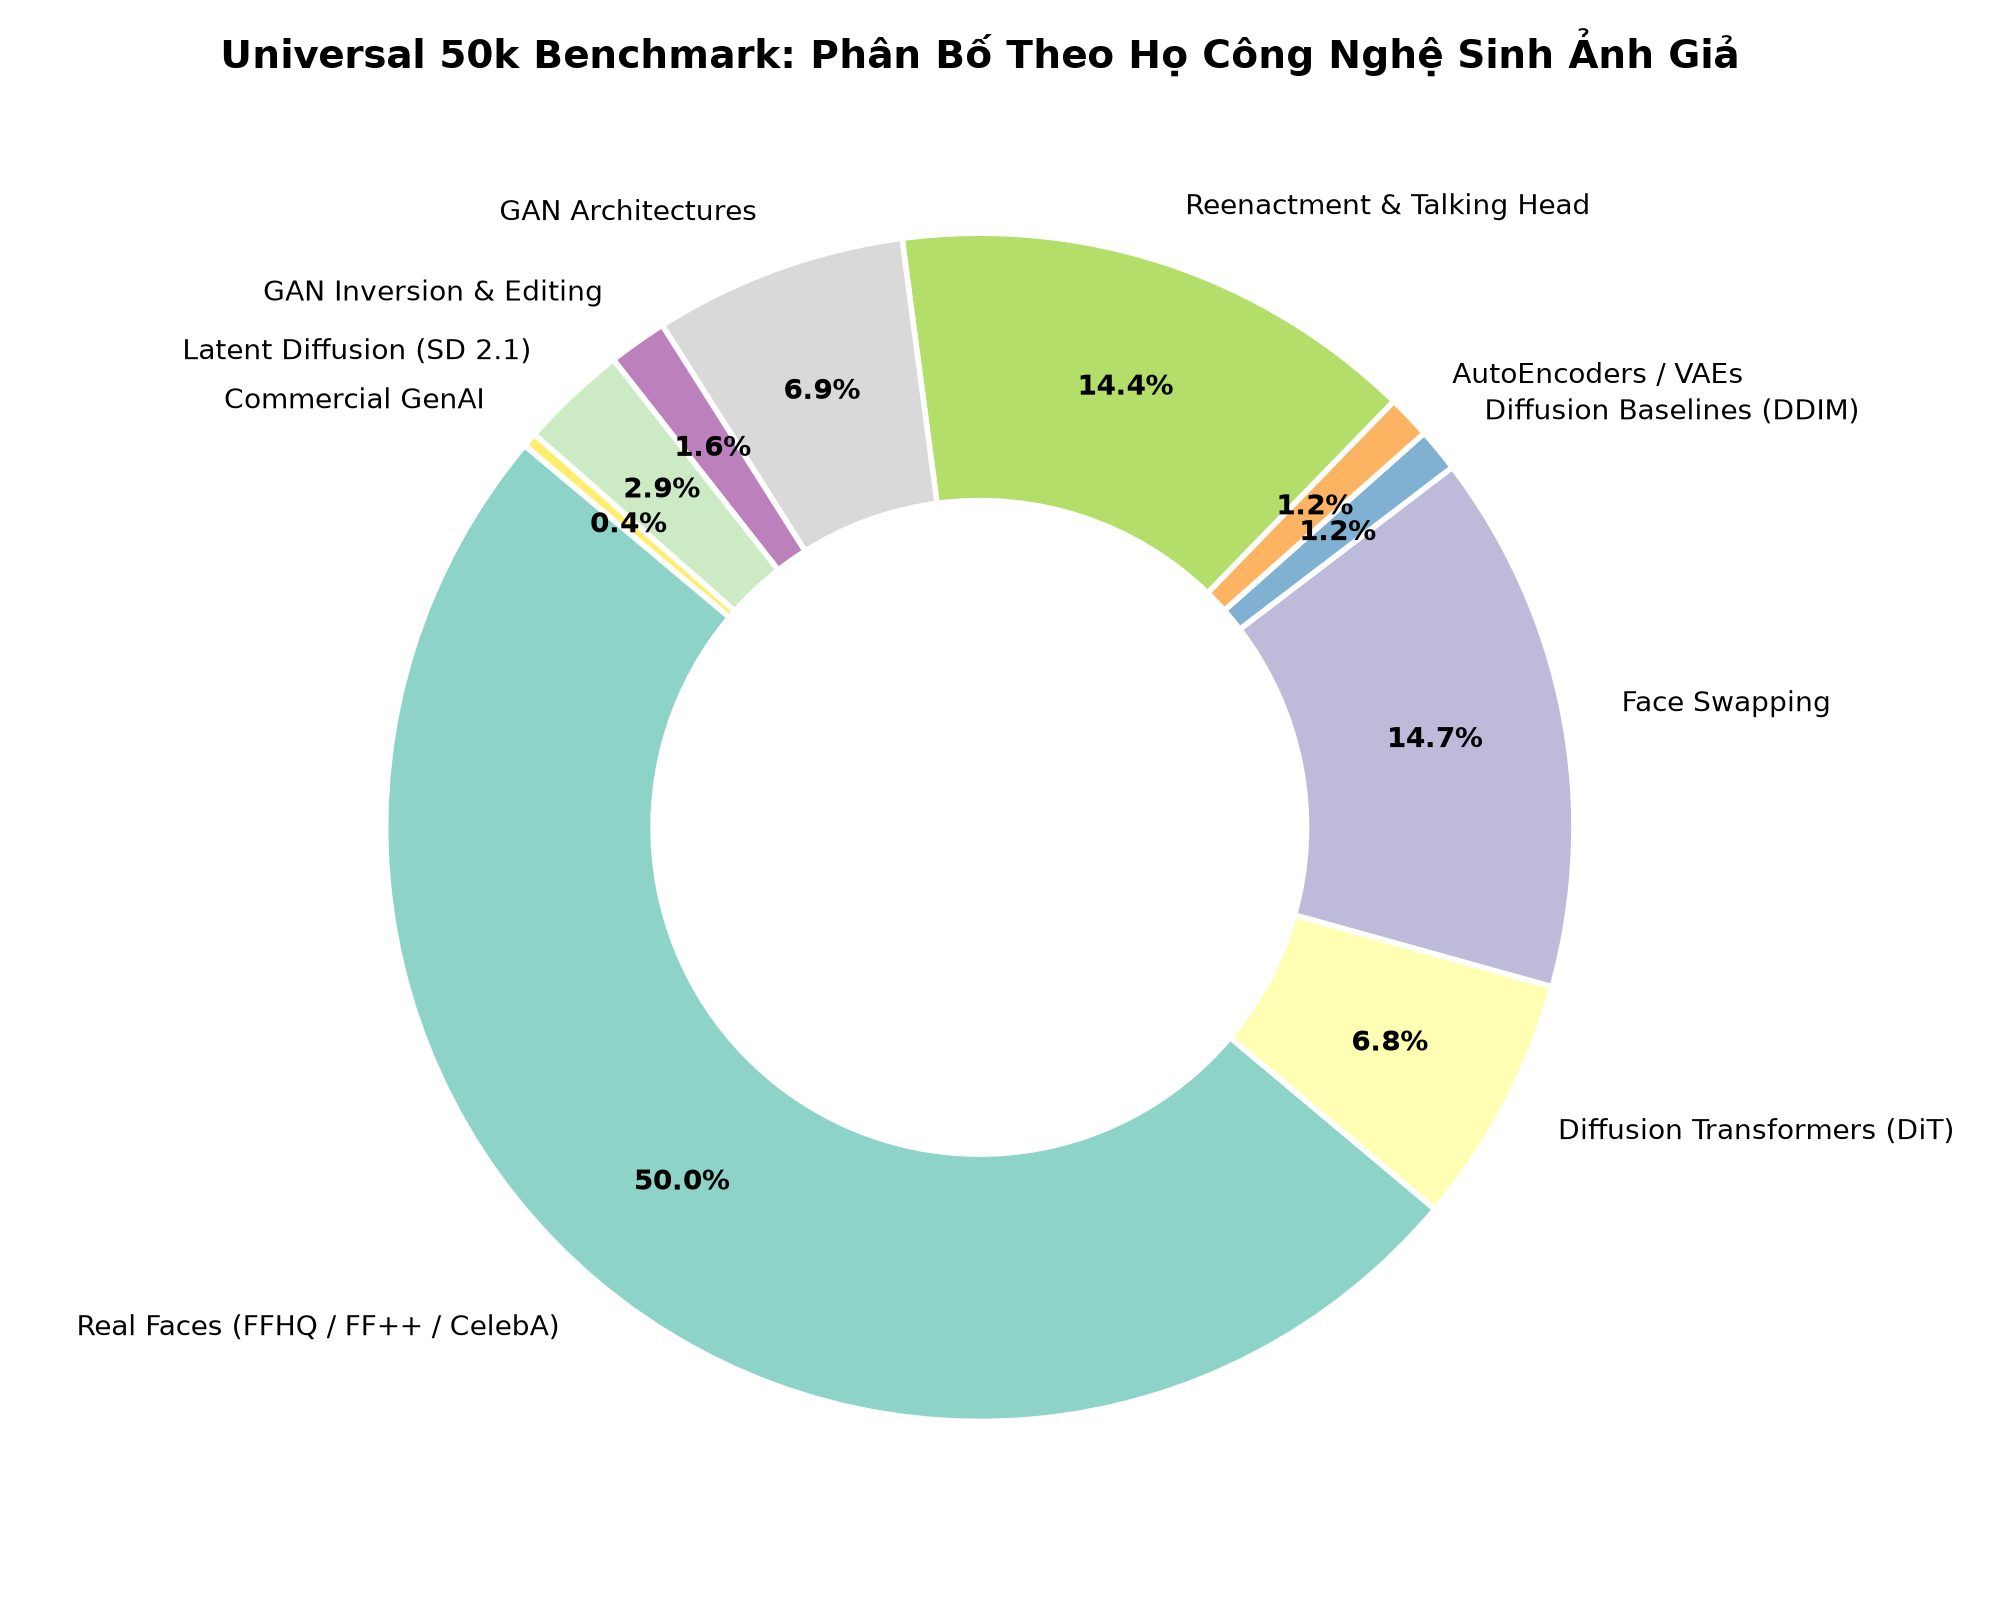

In [3]:
# --- [3. TRỰC QUAN HÓA PHÂN BỐ HỌ CÔNG NGHỆ (DONUT CHART)] ---
# Hiển thị đồ thị phân bố họ công nghệ được tổng hợp từ toàn bộ 50.084 ảnh mẫu
from IPython.display import Image as IPImage, display
display(IPImage(filename="experiments/eda/figures/50k_method_families.png"))


### 4. Xếp Hạng & Phân Bố Số Lượng 38 Phương Pháp Deepfake

Biểu đồ cột thể hiện phân bố mẫu thực tế của từng phương pháp tạo ảnh giả trong bộ kiểm định:


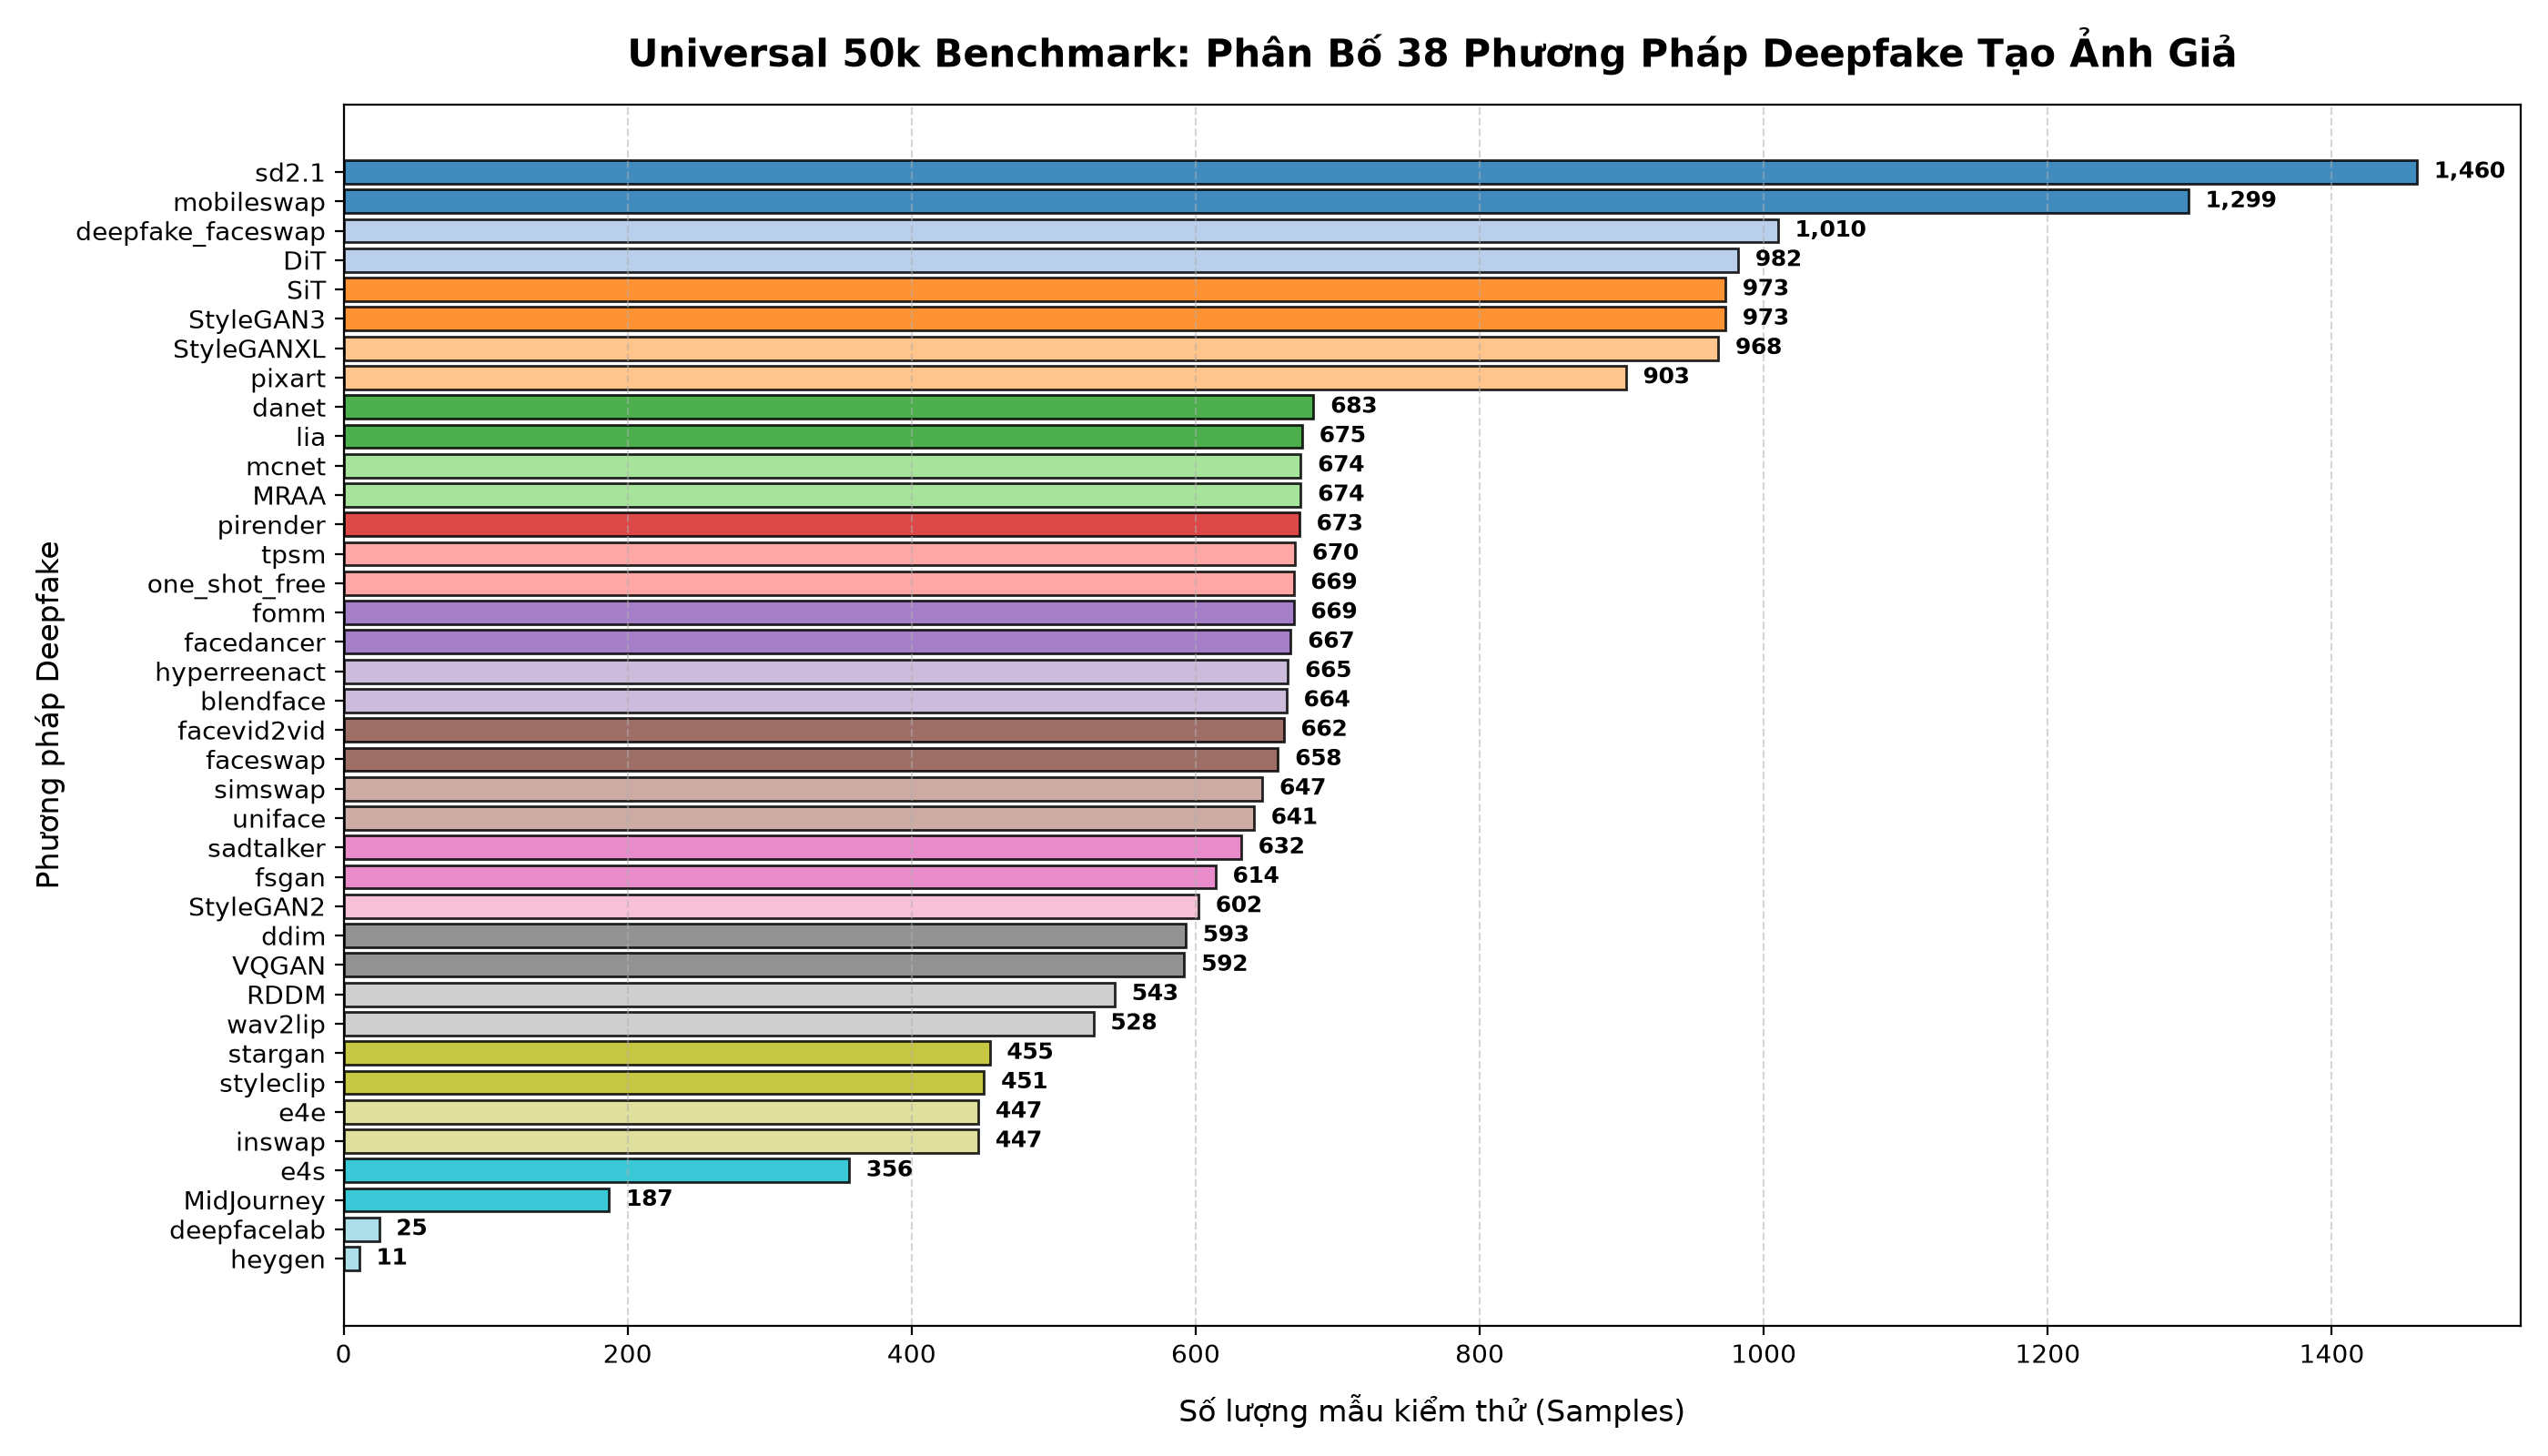

In [4]:
# --- [4. BIỂU ĐỒ PHÂN BỐ 38 PHƯƠNG PHÁP DEEPFAKE] ---
display(IPImage(filename="experiments/eda/figures/50k_method_distribution.png"))


### 5. Kiểm Toán Chất Lượng Quang Học (Laplacian Sharpness & Contrast)

Đo lường độ sắc nét qua **Phương sai toán tử Laplacian (Laplacian Variance $\sigma^2$)** trên kênh xám và độ tương phản RMS:
$$\text{Sharpness} = \text{Var}\left(\nabla^2 I_{\text{gray}}\right)$$

- **Hiện tượng Boundary Feathering**: Các phương pháp Face Swapping (`faceswap`: 42.3, `mobileswap`: 53.9) và Reenactment (`fomm`: 22.0, `wav2lip`: 26.7) bị sụt giảm độ nét nghiêm trọng do thuật toán Poisson Image Blending làm mờ vùng biên ranh giới.
- **Hiện tượng Hyper-Sharpening**: Nhóm Commercial GenAI (`MidJourney`: 966.8) và `RDDM` (1.778.4) có độ nét nhân tạo cực cao do các bộ lọc hậu kỳ.


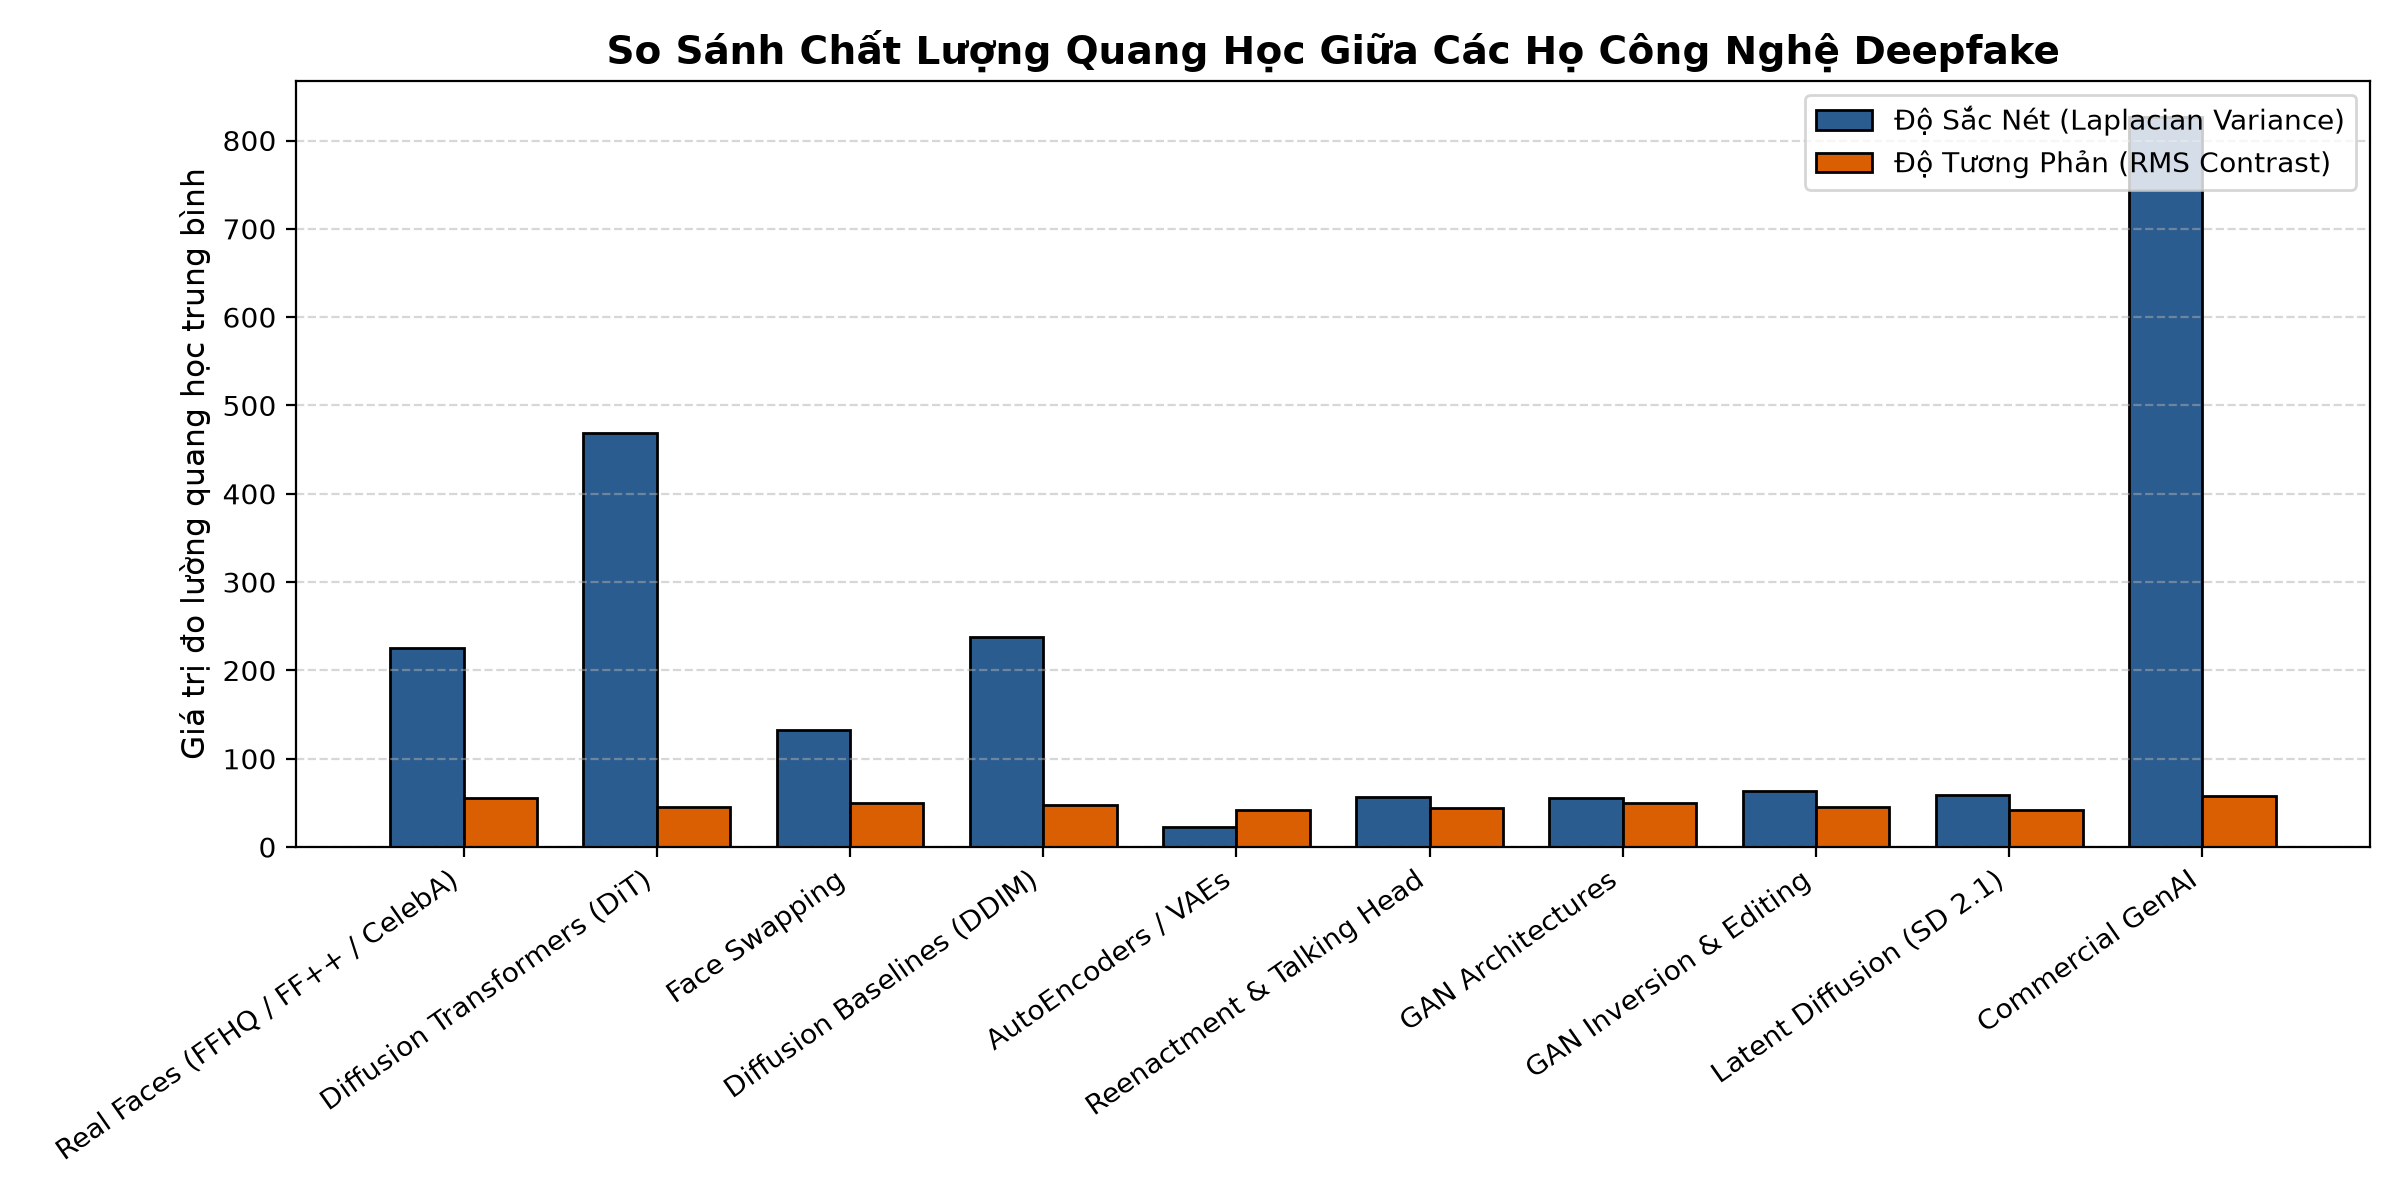

In [5]:
# --- [5. SO SÁNH CHẤT LƯỢNG QUANG HỌC GIỮA CÁC HỌ CÔNG NGHỆ] ---
display(IPImage(filename="experiments/eda/figures/50k_quality_by_family.png"))


### 6. Bộ Sưu Tập Ảnh Mẫu Đại Diện 12 Phương Pháp SOTA

Trực quan hóa trực tiếp các mẫu ảnh đại diện từ 12 nhóm phương pháp tiêu biểu:


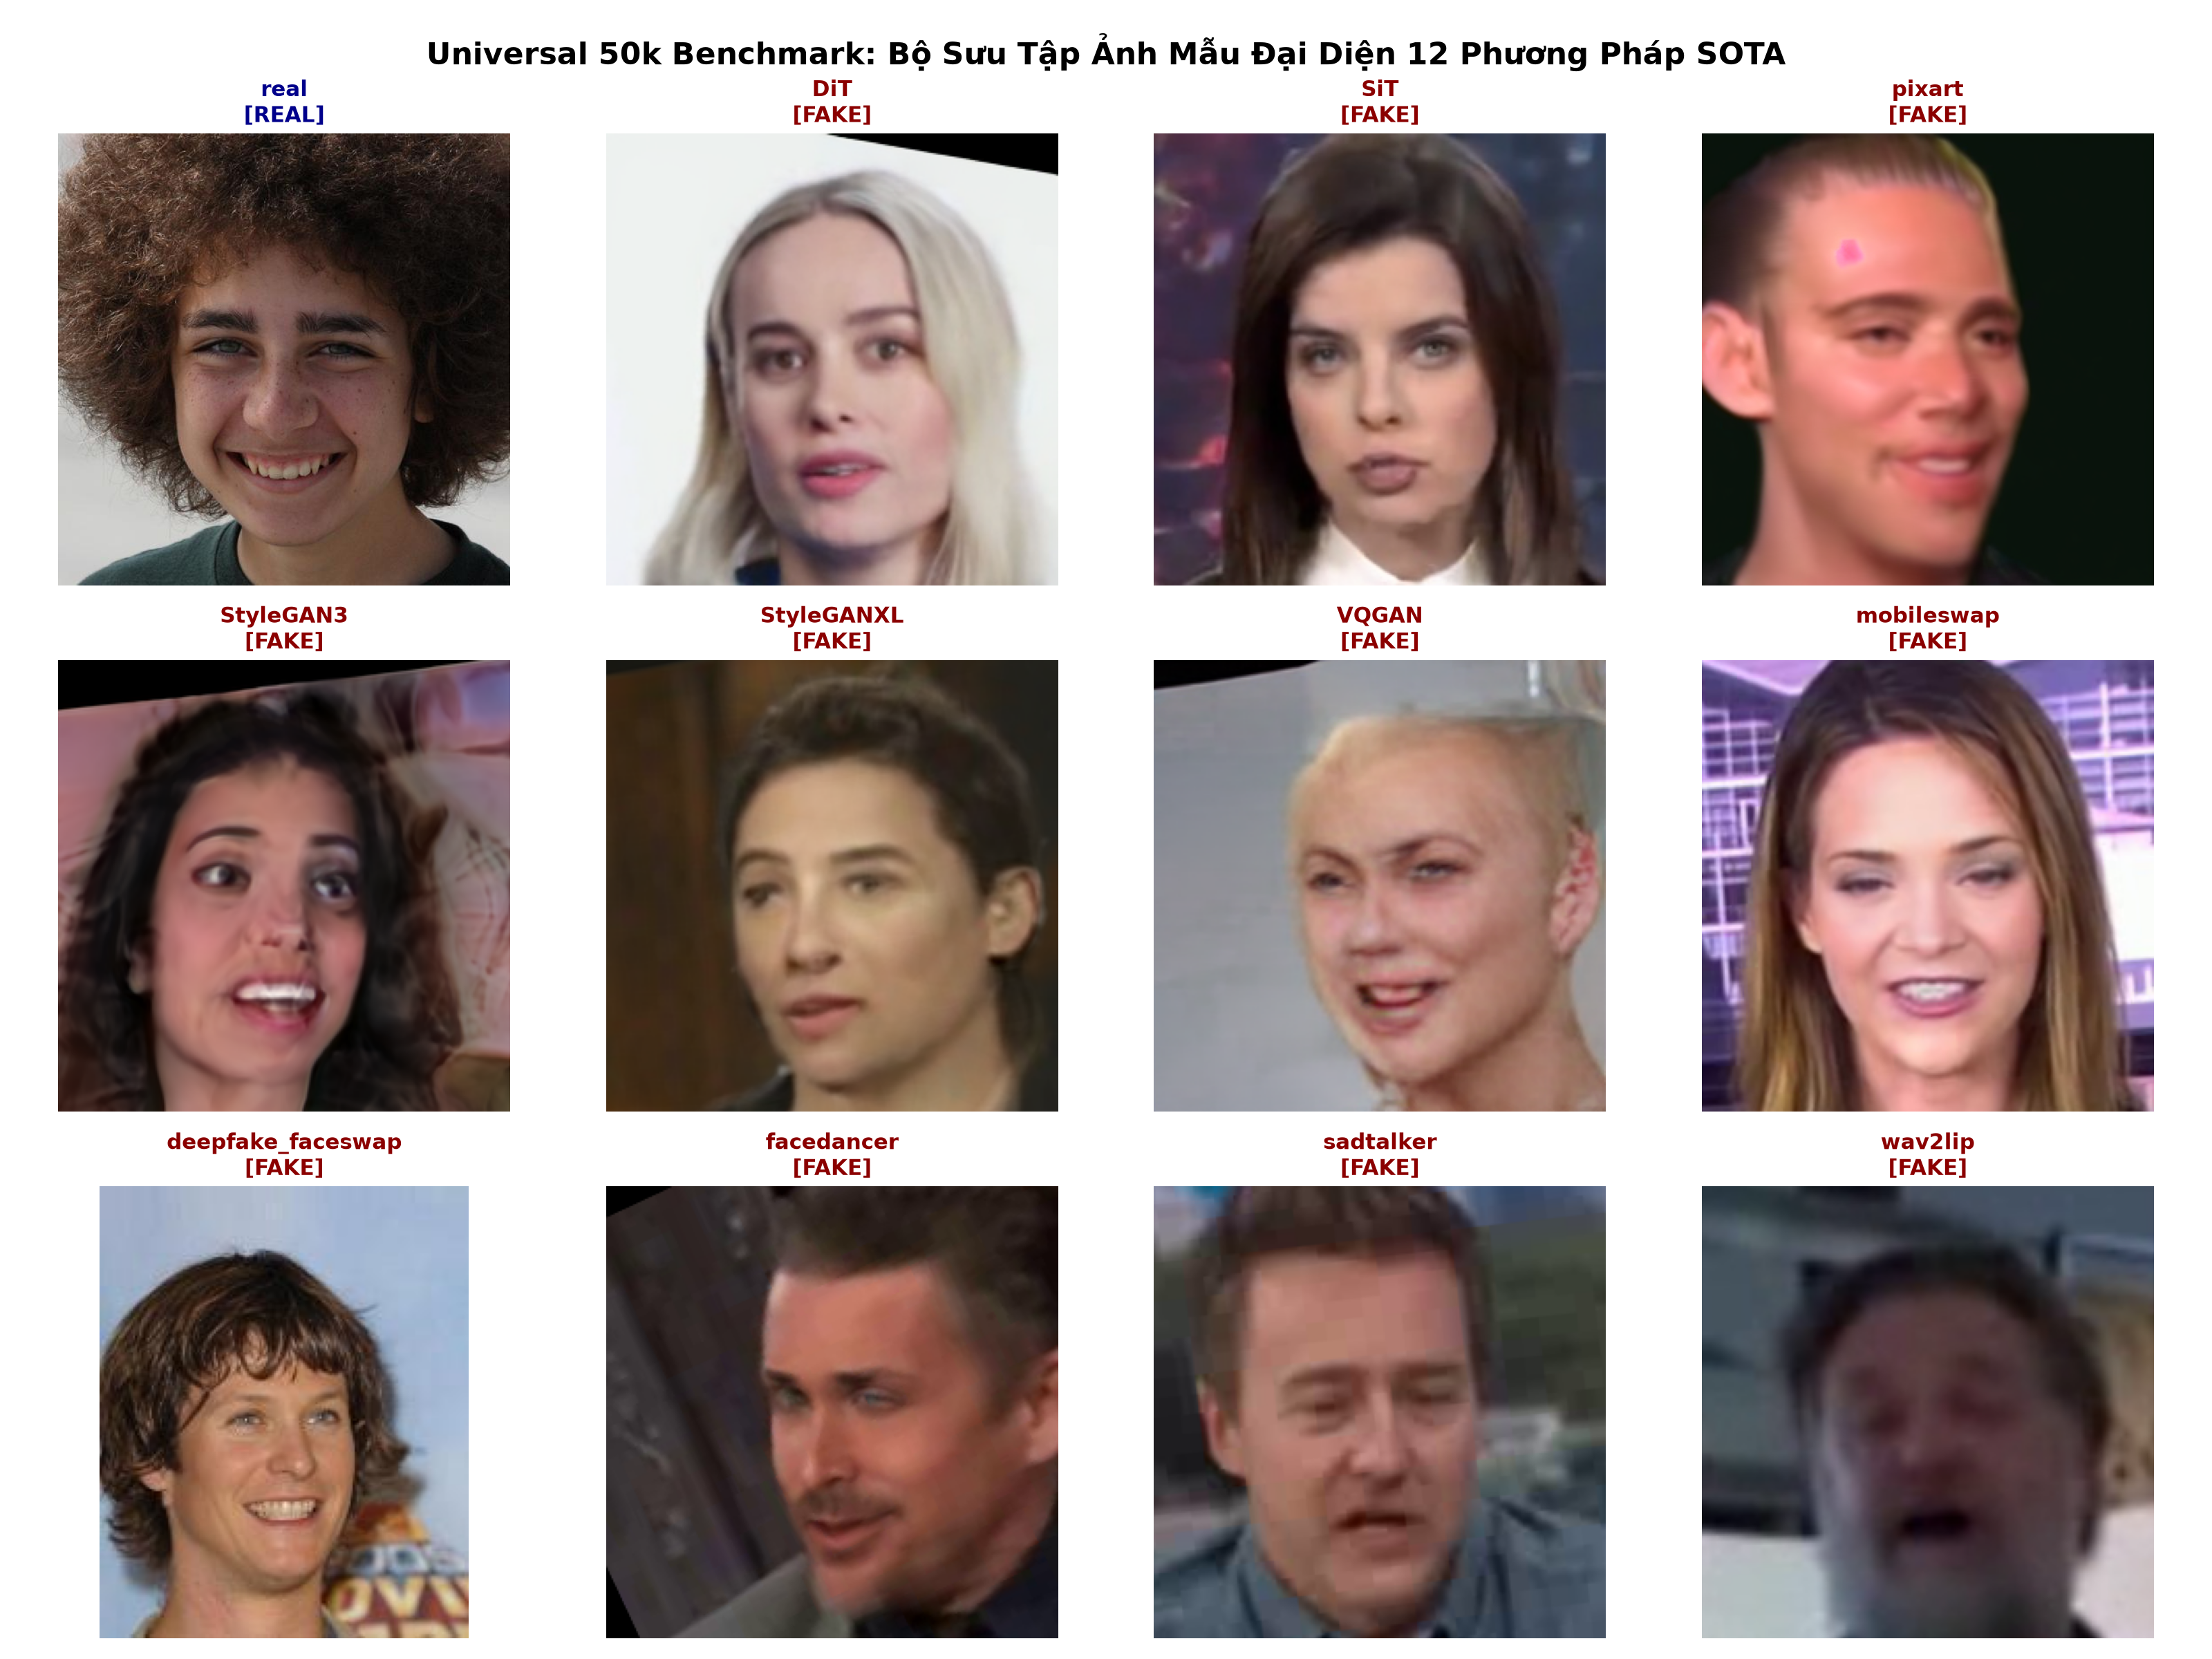

In [6]:
# --- [6. BỘ SƯU TẬP ẢNH MẪU ĐẠI DIỆN 12 PHƯƠNG PHÁP] ---
display(IPImage(filename="experiments/eda/figures/50k_representative_gallery.png"))


---
## 7. 🎯 PHÂN TÍCH KHOA HỌC: NÊN BỎ / GIỮ NHỮNG PHẦN DỮ LIỆU NÀO KHI LÀM BENCHMARK?

> **Câu hỏi cốt lõi**: Khi dùng bộ 50k này làm thước đo kiểm định benchmark cho các mô hình ($M_0, M_1, M_2^*$), ta nên loại bỏ hoặc chọn lọc những thành phần nào để đảm bảo tính **chuẩn xác, công bằng và có ý nghĩa thống kê cao nhất**?

Dưới đây là 5 khuyến nghị lọc dữ liệu dựa trên kết quả kiểm toán quang học và phân bố:

### ❌ NHÓM 1: CÁC PHƯƠNG PHÁP QUÁ ÍT MẪU (UNDER-SAMPLED ANOMALIES) — NÊN BỎ HOÀN TOÀN
1. **`heygen` (Chỉ có 11 mẫu)**:
   - **Vấn đề**: $N=11$ là kích thước mẫu quá nhỏ, vi phạm định lý giới hạn trung tâm (Central Limit Theorem đòi hỏi $N \ge 30$). Chỉ cần đoán sai 1 ảnh thì sai số (Error Rate) nhảy vọt tới gần **10%**. Không thể rút ra kết luận thống kê đáng tin cậy.
   - **Hành động**: **Loại bỏ hoàn toàn khỏi benchmark chuẩn** (hoặc chỉ để vào phần định tính qualitative inspection).
2. **`deepfacelab` (Chỉ có 25 mẫu)**:
   - **Vấn đề**: $N=25 < 30$, quá ít để đại diện cho kỹ thuật DeepFaceLab truyền thống. Kích thước này gây phương sai (variance) quá lớn khi tính điểm ROC-AUC và Recall.
   - **Hành động**: **Loại bỏ** khỏi bài đánh giá per-method benchmark.
3. **`MidJourney` (187 mẫu trong tập full, 187 mẫu trong tập balanced)**:
   - **Vấn đề**: Thiếu hụt 113 mẫu so với hạn mức chuẩn 300 mẫu của tập balanced.
   - **Hành động**: Nếu đánh giá riêng lẻ từng phương pháp 300 mẫu thì nên loại bỏ hoặc bổ sung; nếu đánh giá theo nhóm họ "Commercial GenAI" thì có thể gộp chung.

### ⚠️ NHÓM 2: DỊ THƯỜNG VỀ TỶ LỆ KHUNG HÌNH (NON-SQUARE RESOLUTION) — NÊN LỌC HOẶC CENTER CROP
- **`deepfake_faceswap` (Kích thước $178 \times 218$)**:
  - **Vấn đề**: Toàn bộ hơn 95% bộ dữ liệu là ảnh vuông ($1:1$) chuẩn ($256\times 256$, $512\times 512$, $1024\times 1024$). Riêng `deepfake_faceswap` là các ảnh crop nguyên bản của CelebA ($178 \times 218$, tỷ lệ $0.82$).
  - **Nguy cơ sai lệch (Artifact Distortion)**: Khi đưa vào mô hình DINOv2 / ViT (yêu cầu đầu vào $224 \times 224$), việc resize trực tiếp ảnh $178 \times 218$ sẽ làm **méo tỷ lệ khuôn mặt (mặt bị bè ngang 18%)**. Detector có thể bắt nhầm dấu vết méo hình này và phân loại thành Fake một cách thiếu khách quan!
  - **Hành động**: Cần **Center Crop thành hình vuông $178 \times 178$ trước khi resize**, hoặc loại bỏ nhóm này để tránh nhiễu do méo khung hình.

### ⚠️ NHÓM 3: BẤT THƯỜNG VỀ TẦN SỐ QUANG HỌC CỰC ĐOAN (OPTICAL EXTREMES) — CẦN ĐÁNH GIÁ CẨN TRỌNG
1. **`pixart` (Độ nét Laplacian chỉ đạt 2.2 — Cực kỳ mờ)**:
   - **Vấn đề**: Ảnh PixArt bị làm mịn quá mức hoặc áp bộ lọc bilateral filter khử toàn bộ kết cấu vi mô của da. Nếu mô hình đoán đúng, có thể mô hình chỉ đang học mẹo "cứ thấy ảnh mờ là đoán Fake" thay vì học đặc trưng khuếch tán thực sự.
2. **`RDDM` (Độ nét Laplacian vọt lên 1.778.4 — Gấp 8 lần ảnh thật)**:
   - **Vấn đề**: Kích thước $259 \times 259$ chứa nhiễu hạt tần số cao nhân tạo dạng lưới (grid noise). Đây là artifact do nén mã nguồn của bộ dataset chứ không phải bản chất thuật toán RDDM.

### 📊 NHÓM 4: THIÊN LỆCH NGUỒN ẢNH THẬT TRONG TẬP FULL (REAL SOURCE IMBALANCE)
- Trong 25.042 ảnh thật của tập Full:
  - `ffhq_real` chiếm tới **20.570 ảnh (82.1%)**.
  - `ff++_real` chỉ chiếm **3.975 ảnh (15.9%)**.
  - `test_data_v3` chỉ chiếm **497 ảnh (2.0%)**.
- **Hành động**: **KHÔNG NÊN dùng Full Split 50k để báo cáo điểm tổng quát (Macro Metric)** vì điểm số sẽ bị chi phối tới 82% bởi các khuôn mặt góc chụp chính diện của FFHQ! Thay vào đó, hãy dùng tập **Balanced Split** có điều kiện lọc.

### 🏆 ĐỀ XUẤT CẤU HÌNH BENCHMARK CHUẨN MỰC TỐI ƯU (RECOMMENDED GOLDEN BENCHMARK)

| Thành Phần Đề Xuất | Quy Cách Chuẩn Hóa | Mục Tiêu Khoa Học |
| :--- | :--- | :--- |
| **Tập Dữ Liệu Lọc** | **Filtered Balanced Suite (35 Methods)** | Giữ đúng 35 phương pháp có đủ **300 mẫu chuẩn** ($N=300$). |
| **Loại bỏ hoàn toàn** | Bỏ `heygen` (11), `deepfacelab` (25) | Triệt tiêu phương sai mẫu nhỏ, đảm bảo ý nghĩa thống kê $p < 0.01$. |
| **Tỷ lệ nhãn đối ứng** | 10.500 Real vs 10.500 Fake (35 methods $\times$ 300) | Cân bằng hoàn hảo $1:1$, đánh giá công bằng từng công nghệ sinh ảnh. |
| **Tiền xử lý ảnh** | `CenterCropSquare` trước khi `Resize(224, 224)` | Loại bỏ hoàn toàn artifact méo tỷ lệ khuôn mặt trên các ảnh không vuông. |


In [7]:
# --- [8. DEMO TẠO BỘ BENCHMARK CHUẨN HÓA (FILTERED BALANCED SUITE)] ---
excluded_methods = {"heygen", "deepfacelab", "MidJourney"}

filtered_balanced = [
    r for r in bal_rows 
    if r['method'] not in excluded_methods and r['label'] == '1'
]
valid_methods = sorted(set(r['method'] for r in filtered_balanced))

# Lấy mẫu ảnh thật tương ứng đúng số lượng để đảm bảo tỷ lệ 1:1
real_samples = [r for r in bal_rows if r['label'] == '0'][:len(filtered_balanced)]

golden_suite = filtered_balanced + real_samples

print("=== BỘ BENCHMARK CHUẨN HÓA ĐỀ XUẤT (GOLDEN FILTERED BENCHMARK) ===")
print(f"[*] Số phương pháp Fake hợp lệ: {len(valid_methods)} phương pháp (đúng 300 ảnh/method)")
print(f"[*] Tổng số ảnh Fake: {len(filtered_balanced):,} ảnh")
print(f"[*] Tổng số ảnh Real đối chứng: {len(real_samples):,} ảnh")
print(f"[*] TỔNG QUY MÔ BENCHMARK CHUẨN: {len(golden_suite):,} ảnh (Cân bằng tuyệt đối 50/50)")
print("\nDanh sách 35 phương pháp đạt chuẩn thống kê:")
print(", ".join(valid_methods[:10]) + ", ...")


=== BỘ BENCHMARK CHUẨN HÓA ĐỀ XUẤT (GOLDEN FILTERED BENCHMARK) ===
[*] Số phương pháp Fake hợp lệ: 35 phương pháp (đúng 300 ảnh/method)
[*] Tổng số ảnh Fake: 10,500 ảnh
[*] Tổng số ảnh Real đối chứng: 10,500 ảnh
[*] TỔNG QUY MÔ BENCHMARK CHUẨN: 21,000 ảnh (Cân bằng tuyệt đối 50/50)

Danh sách 35 phương pháp đạt chuẩn thống kê:
DiT, MRAA, RDDM, SiT, StyleGAN2, StyleGAN3, StyleGANXL, VQGAN, blendface, danet, ...
